## Library imports

In [ ]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ['HF_HOME'] = os.getcwd() + "/cache/"

import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset, Dataset, DatasetDict
from evaluate import load
from transformers.utils import logging
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from IPython.display import display

In [2]:
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device('cpu')

print(device)

cuda


## Data loading

In [3]:
verbatim_df = pd.read_csv("../data/verbatim_2026_07_31.csv", sep=";", encoding="utf-8")
dimensions_df = pd.read_csv("../data/Zscores_dimensions.csv", encoding="utf-8")

display(verbatim_df.head())
display(dimensions_df.head())

,ID expérience,Titre,Description
0,280027,ANAH - programme habiter mieux,Nous avons déposé un dossier complet à l'Anah ...
1,280008,Retard de distribution du courrier à la Poste,"Bonjour,depuis plusieurs mois, la Poste distri..."
2,271405,LA PRIME A LA CASSE,J’ai fait une demande de prime à la casse. Ach...
3,279964,Obtention de la copie d'un procès verbal de ré...,Refus du Maire après plusieurs demandes.En fin...
4,279910,Gendarmerie : secret professionnel non respecté,Lors d'un appel au secours (112) faite par une...


,id_experience,satisfaction,perplexite,desillusion,contestation,detresse
0,280177,0.035954,0.090599,1.120834,0.772288,1.055633
1,280171,-0.180208,0.948308,0.379088,0.285955,-0.379695
2,280163,1.358469,-0.552201,-1.197296,-1.038216,-1.397118
3,280174,0.310334,0.047712,-0.086420,-0.445949,1.304659
4,280169,-0.742041,1.124622,1.153119,-0.514206,0.265893


In [ ]:
print(len(verbatim_df.index))
verbatim_df = verbatim_df.drop_duplicates("ID expérience")
print(len(verbatim_df.index))

160983
160962
160962
160962


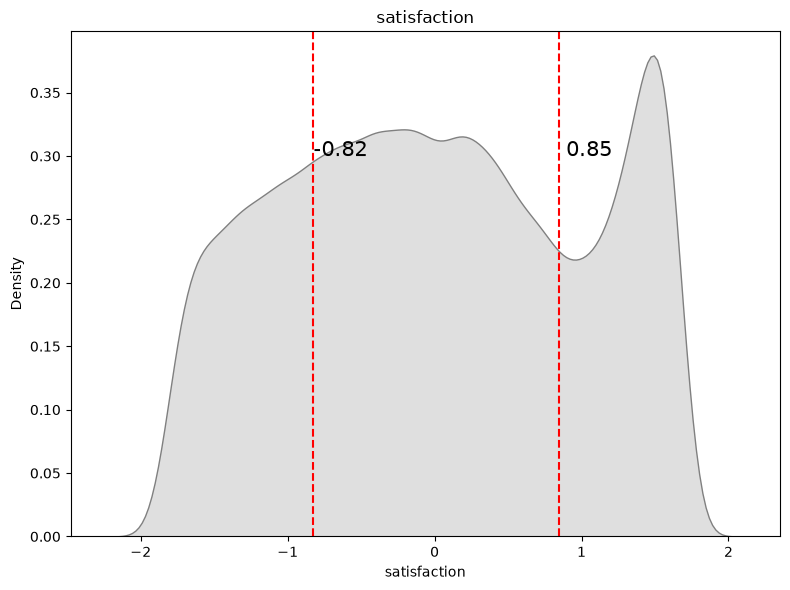

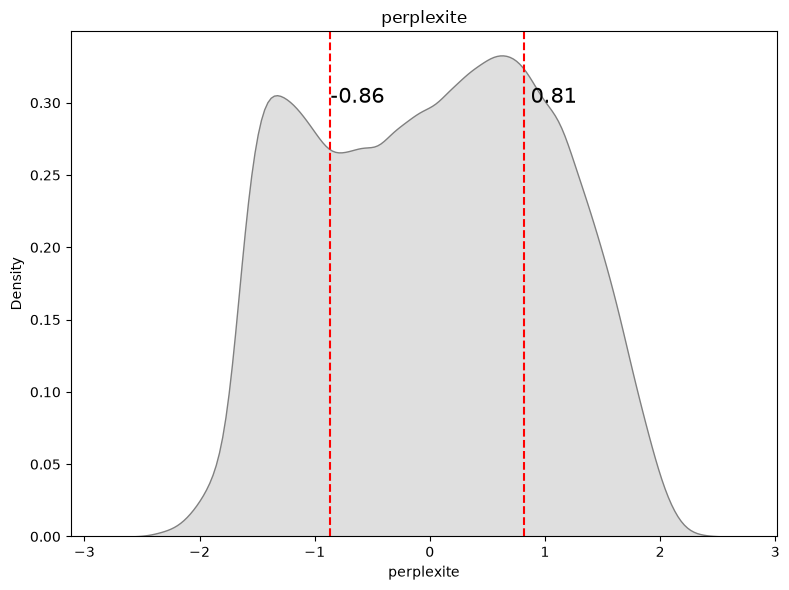

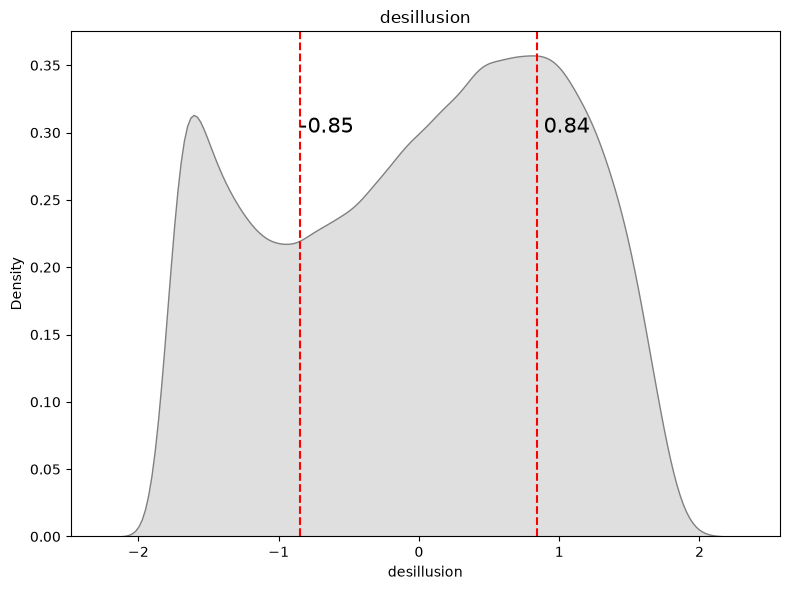

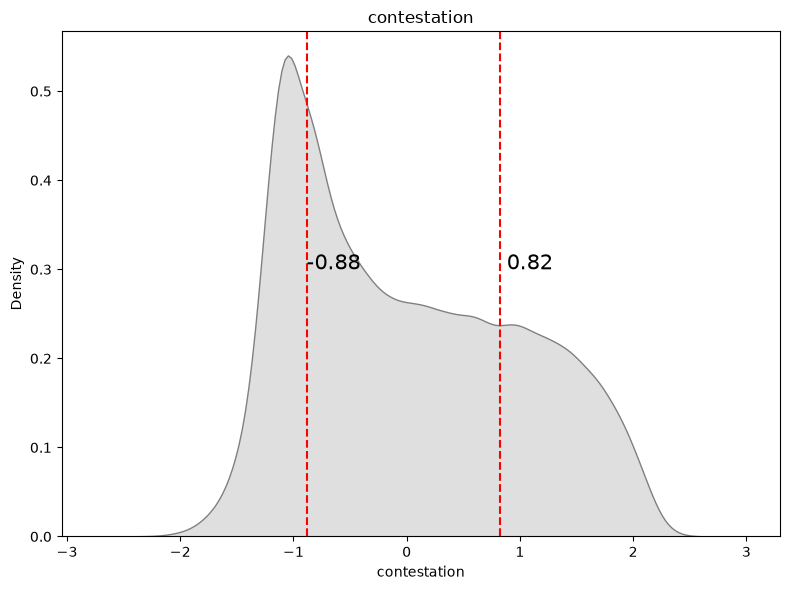

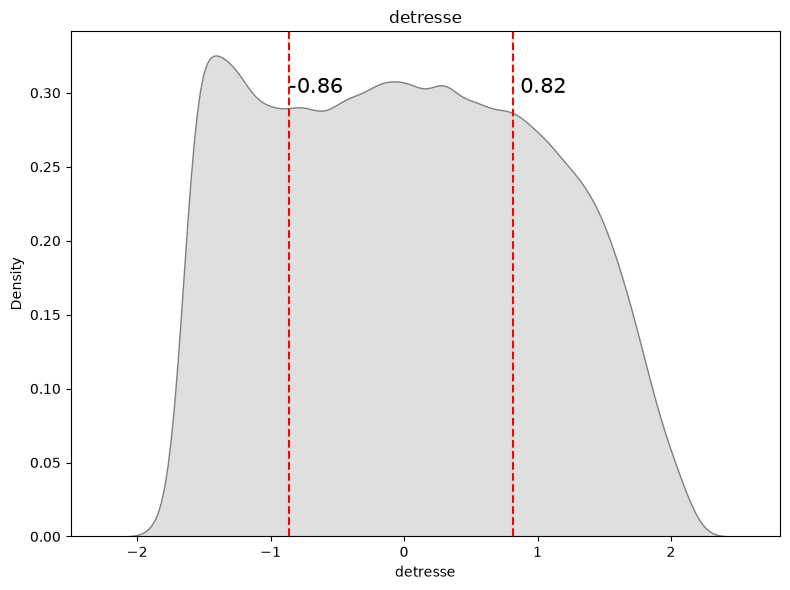

In [4]:
dimensions = ["satisfaction", "perplexite", "desillusion", "contestation", "detresse"]

for dim in dimensions:
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.kdeplot(dimensions_df[dim], color='grey', ax=ax, fill=True)

    q25 = dimensions_df[dim].quantile(0.25)
    q75 = dimensions_df[dim].quantile(0.75)

    ax.axvline(q25, color='red', linestyle="--")
    ax.text(q25, 0.3, f"{q25: .2f}", fontsize=15)
    ax.axvline(q75, color='red', linestyle="--")
    ax.text(q75, 0.3, f"{q75: .2f}", fontsize=15)

    ax.set_title(dim)
    fig.tight_layout()
    plt.show()

In [5]:
for dim in dimensions:
    dimensions_df[f"{dim}_nli"] = (dimensions_df[dim] < 0).astype(np.int8)

dimensions_df[[f"{dim}_nli" for dim in dimensions]]

,satisfaction_nli,perplexite_nli,desillusion_nli,contestation_nli,detresse_nli
0,0,0,0,0,0
1,1,0,0,0,1
2,0,1,1,1,1
3,0,0,1,1,0
4,1,0,0,1,0
...,...,...,...,...,...
160957,1,1,0,1,0
160958,1,0,1,1,0
160959,0,1,1,1,1
160960,1,0,1,1,1


In [6]:
verbatim_df["full_comment"] = verbatim_df["Titre"] + "\n\n" + verbatim_df["Description"]

In [7]:
verbatim_df.rename(columns={"ID expérience": "id_experience"}, inplace=True)

merged_df = verbatim_df.merge(dimensions_df, on="id_experience", how="inner")
merged_df.head()

,id_experience,Titre,Description,full_comment,satisfaction,perplexite,desillusion,contestation,detresse,satisfaction_nli,perplexite_nli,desillusion_nli,contestation_nli,detresse_nli
0,280027,ANAH - programme habiter mieux,Nous avons déposé un dossier complet à l'Anah ...,ANAH - programme habiter mieux\n\nNous avons d...,-0.912913,1.518875,0.866863,0.573995,0.762334,1,0,0,0,0
1,280008,Retard de distribution du courrier à la Poste,"Bonjour,depuis plusieurs mois, la Poste distri...",Retard de distribution du courrier à la Poste...,-0.911917,0.681989,0.959378,0.668772,-0.799335,1,0,0,0,1
2,271405,LA PRIME A LA CASSE,J’ai fait une demande de prime à la casse. Ach...,LA PRIME A LA CASSE\n\nJ’ai fait une demande d...,1.056911,0.986705,0.550895,0.945588,0.049118,0,0,0,0,0
3,279964,Obtention de la copie d'un procès verbal de ré...,Refus du Maire après plusieurs demandes.En fin...,Obtention de la copie d'un procès verbal de ré...,-0.446126,-0.139423,0.010456,1.296667,-0.880162,1,1,0,0,1
4,279910,Gendarmerie : secret professionnel non respecté,Lors d'un appel au secours (112) faite par une...,Gendarmerie : secret professionnel non respect...,-0.589430,0.939419,-0.398534,1.710874,0.754765,1,0,1,0,0


In [8]:
train_df, val_df = train_test_split(merged_df, test_size=0.2, random_state=1234)
val_df, test_df = train_test_split(val_df, test_size=0.5, random_state=1234)

print(len(train_df.index), len(val_df.index), len(test_df.index))

128786 16098 16099


In [9]:
dst_emotions = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "valid": Dataset.from_pandas(val_df),
    "test": Dataset.from_pandas(test_df)
})
dst_emotions

DatasetDict({
    train: Dataset({
        features: ['id_experience', 'Titre', 'Description', 'full_comment', 'satisfaction', 'perplexite', 'desillusion', 'contestation', 'detresse', 'satisfaction_nli', 'perplexite_nli', 'desillusion_nli', 'contestation_nli', 'detresse_nli', '__index_level_0__'],
        num_rows: 128786
    })
    valid: Dataset({
        features: ['id_experience', 'Titre', 'Description', 'full_comment', 'satisfaction', 'perplexite', 'desillusion', 'contestation', 'detresse', 'satisfaction_nli', 'perplexite_nli', 'desillusion_nli', 'contestation_nli', 'detresse_nli', '__index_level_0__'],
        num_rows: 16098
    })
    test: Dataset({
        features: ['id_experience', 'Titre', 'Description', 'full_comment', 'satisfaction', 'perplexite', 'desillusion', 'contestation', 'detresse', 'satisfaction_nli', 'perplexite_nli', 'desillusion_nli', 'contestation_nli', 'detresse_nli', '__index_level_0__'],
        num_rows: 16099
    })
})

In [21]:
labels = ["satisfaction", "perplexite", "desillusion", "contestation", "detresse"]
template = "The emotion of this text is {}"

def expand(batch):
    out = {"premise": [], "hypothesis": [], "label": []}
    for i, text in enumerate(batch["full_comment"]):
        for lab in labels:
            out["premise"].append(text)
            out["hypothesis"].append(template.format(lab))
            out["label"].append(int(batch[f"{lab}_nli"][i]))
    return out

dst_nli = dst_emotions.map(
    expand,
    batched=True,
    remove_columns=dst_emotions["train"].column_names,  # required, since the output has more rows than the input
)
dst_nli

Map:   0%|          | 0/128786 [00:00<?, ? examples/s]

Map:   0%|          | 0/16098 [00:00<?, ? examples/s]

Map:   0%|          | 0/16099 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 643930
    })
    valid: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 80490
    })
    test: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 80495
    })
})

In [24]:
dst_nli["train"][0]

{'premise': "Impossible d'imprimer le contenu de la pré-plainte\n\nImpossible d'imprimer le contenu de la pré-plainte. On peut juste imprimer le numéro du dossier et la liste des pièces à fournir lors de la présentation au commissariat.",
 'hypothesis': 'The emotion of this text is satisfaction',
 'label': 0}

## Model training

### Hyperparameters

In [10]:
training_batch_size = 8
num_epochs = 5
lr = 2e-5
weight_decay = 0.01

### Training setup

In [13]:
model_name = "MoritzLaurer/deberta-v3-large-zeroshot-v2.0"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2).to(device)

config.json:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/970 [00:00<?, ?B/s]

d:\William\Work\ACSS\Projects\Model_emotions\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  870MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

In [25]:
encoded_dataset = dst_nli.map(lambda example: tokenizer(example["premise"], example["hypothesis"], max_length=512, truncation=True), batched=True)

Map:   0%|          | 0/643930 [00:00<?, ? examples/s]

Map:   0%|          | 0/80490 [00:00<?, ? examples/s]

Map:   0%|          | 0/80495 [00:00<?, ? examples/s]

In [26]:
metric_name = "f1"
metric = load(metric_name)


def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return {
        "f1_micro": metric.compute(predictions=predictions, references=labels, average="micro")["f1"],
        "f1_macro": metric.compute(predictions=predictions, references=labels, average="macro")["f1"]
    }

### Training

In [28]:
args = TrainingArguments(
    f"./models/model_emotions",
    eval_strategy="steps",
    save_strategy="steps",
    eval_steps=100,
    logging_steps=100,
    learning_rate=lr,
    per_device_train_batch_size=training_batch_size,
    per_device_eval_batch_size=training_batch_size,
    num_train_epochs=num_epochs,
    weight_decay=weight_decay,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    save_total_limit=3,
    seed=1234
)

trainer = Trainer(
    model,
    args,
    train_dataset=encoded_dataset["train"],
    eval_dataset=encoded_dataset["valid"],
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

ImportError: Using the `Trainer` with `PyTorch` requires `accelerate>=1.1.0`: Please run `pip install transformers[torch]` or `pip install 'accelerate>=1.1.0'`

In [ ]:
logging.set_verbosity_info()

trainer.train()

### Assessing the model

In [ ]:
predictions = trainer.predict(encoded_dataset["test"])
y_pred = predictions.predictions.argmax(-1)
y_true = predictions.label_ids

label_list = ["entailed", "not entailed"]

print(classification_report(y_true, y_pred, target_names=label_list))

In [ ]:
disp = ConfusionMatrixDisplay.from_predictions(
    y_true, 
    y_pred, 
    display_labels=label_list,
    cmap="Blues",
    xticks_rotation="vertical"
)

plt.show()

In [ ]:
log_history = trainer.state.log_history
x = sorted(list({log["step"] for log in log_history}))
y1 = [log["loss"] if "loss" in log else log["train_loss"] for log in list(filter(lambda log: ("loss" in log) or ("train_loss" in log), log_history))]
y2 = [log["eval_loss"] for log in list(filter(lambda log: "eval_loss" in log, log_history))]

if len(x) < len(y1) or len(x) < len(y2):
    print(f"log_history: {log_history}")
    y1 = y1[:len(x)]
    y2 = y2[:len(x)]

fig, ax = plt.subplots()
ax.plot(x, y1, 'r', label="train_loss")
ax.plot(x, y2, 'g', label="eval_loss")
ax.set_ylim(0, 1)
ax.set_xlabel("Step", fontsize='large')
ax.set_ylabel("Loss", fontsize='large')
ax.legend()
plt.tight_layout()